In [16]:
#imports
import pandas as pd
import numpy as np
from google.cloud import bigquery
import matplotlib.pyplot as plt

PROJECT_ID = 'comp90089-507410'

client = bigquery.Client(project=PROJECT_ID)
INTERVAL = 6
MISSING = 0.5

def run_query(query):
    query_job = client.query(query)
    return query_job.to_dataframe()

# Cohort Construction


**Cohort definition**
* Adult ICU patients with mechanical ventilation
    * Defined as first planned ICU extubation per patient with preceding invasive ventilation during the same icu stay (adapted from Zhao et al. 2021)
    * Unplanned events excluded
* First extubation
    * First planned extubation per patient, different to Zhao et al.
    * Unplanned Extubation (patient-initiated) itemid: 225468
    * Unplanned Extubation (non-patient-initiated) itemid: 225477
    * Extubation itemid: 227194
* $6$ hours of valid ( $\leq 50\%$ overall missingness) physiological data before extubation, assessed before imputation
* Exclusion Criteria:
    * Do-Not-Intubate (DNI) or Do Not Resuscitate (DNR)
    * Unplanned extubation - patient - and non patient initiated (procedure events)
* Missing status code retained as unkown

In [17]:
# Shared cohort definition used by every extraction query.
COHORT_CTES = """
WITH base AS (
    SELECT i.*, ps.starttime AS `extubation_time`, d.label AS `extubation_type`
    FROM `physionet-data.mimiciv_3_1_derived.icustay_detail` AS i
    JOIN  `physionet-data.mimiciv_3_1_icu.procedureevents` AS ps
    ON i.stay_id = ps.stay_id
    JOIN  `physionet-data.mimiciv_3_1_icu.d_items` AS d
    ON ps.itemid = d.itemid
    WHERE (ps.itemid = 227194 OR ps.itemid = 225468 OR ps.itemid = 225477)
    AND i.icu_intime <= ps.starttime AND i.icu_outtime >= ps.starttime
), adult AS (
    SELECT *
    FROM base
    WHERE admission_age >= 18
), planned_extubation AS(
    SELECT *
    FROM adult
    WHERE extubation_type = 'Extubation'
), first_extubation AS (
    SELECT *
    FROM planned_extubation QUALIFY ROW_NUMBER() OVER (PARTITION BY subject_id ORDER BY extubation_time, stay_id) = 1
), vent_exists AS (
    SELECT *
    FROM first_extubation AS fe
    WHERE EXISTS (
        SELECT 1
        FROM `physionet-data.mimiciv_3_1_derived.ventilation` AS v
        WHERE v.stay_id = fe.stay_id AND v.ventilation_status = 'InvasiveVent'
        AND v.starttime < fe.extubation_time
    )
), DNR_DNI_exclusion AS (
    SELECT ve.*, value, ce.charttime
    FROM vent_exists as ve
    LEFT JOIN `physionet-data.mimiciv_3_1_icu.chartevents` as ce
    ON ve.stay_id = ce.stay_id AND ce.charttime <= extubation_time AND ce.itemid = 223758 AND ce.storetime <= ve.extubation_time
    QUALIFY ROW_NUMBER() OVER (PARTITION BY ve.subject_id ORDER BY ce.charttime DESC, ce.storetime DESC) = 1
), DNR_DNI_excluded AS (
    SELECT * EXCEPT (value, charttime)
    FROM DNR_DNI_exclusion AS dde
    WHERE NOT (dde.value = 'DNR / DNI' OR dde.value = 'DNR' OR dde.value = 'DNI') or dde.value IS NULL
)
"""

counts = COHORT_CTES + """
SELECT 1 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'base' AS `Stage` FROM base
UNION ALL
SELECT 2 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove non-adult' AS `Stage` FROM adult
UNION ALL
SELECT 3 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove unplanned extubation (patient and non-patient initiated)' AS `Stage` FROM planned_extubation
UNION ALL
SELECT 4 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove non-first extubation' AS `Stage` FROM first_extubation
UNION ALL
SELECT 5 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove patients without invasive ventilation prior to extubation' AS `Stage` FROM vent_exists
UNION ALL
SELECT 6 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove patients with DNR/DNI orders' AS `Stage` FROM DNR_DNI_excluded
ORDER BY `Step`
"""
counts_result = run_query(counts)
counts_result


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,Step,Patients,Stage
0,1,21981,base
1,2,21981,remove non-adult
2,3,21513,remove unplanned extubation (patient and non-p...
3,4,21513,remove non-first extubation
4,5,19178,remove patients without invasive ventilation p...
5,6,19021,remove patients with DNR/DNI orders


In [18]:
# Outcome timestamps are metadata, never model predictors.
cohort_query = COHORT_CTES + """
, outcome_times AS (
    SELECT dde.*,
        (SELECT MIN(a.deathtime)
         FROM `physionet-data.mimiciv_3_1_hosp.admissions` AS a
         WHERE a.hadm_id = dde.hadm_id AND a.subject_id = dde.subject_id
           AND a.deathtime > dde.extubation_time
           AND a.deathtime <= dde.extubation_time + INTERVAL 48 HOUR
        ) AS death_time_48h,
        (SELECT MIN(ps.starttime)
         FROM `physionet-data.mimiciv_3_1_icu.procedureevents` AS ps
         WHERE ps.subject_id = dde.subject_id AND ps.hadm_id = dde.hadm_id
           AND ps.itemid = 224385
           AND ps.starttime > dde.extubation_time
           AND ps.starttime <= dde.extubation_time + INTERVAL 48 HOUR
        ) AS reintubation_time_48h
    FROM DNR_DNI_excluded AS dde
)
SELECT ot.*,
    p.anchor_year, p.anchor_year_group,
    CAST(ot.death_time_48h IS NOT NULL AS INT64) AS death_within_48_hours,
    CAST(ot.reintubation_time_48h IS NOT NULL AS INT64) AS reintubation_within_48_hours,
    icu.first_careunit AS icu_type_at_admission,
    DATETIME_DIFF(ot.extubation_time, ot.icu_intime, SECOND) / 3600.0 AS icu_hours_before_extubation,
    DATETIME_DIFF(ot.extubation_time, ot.admittime, SECOND) / 3600.0 AS hospital_hours_before_extubation
FROM outcome_times AS ot
LEFT JOIN `physionet-data.mimiciv_3_1_icu.icustays` AS icu
    ON ot.stay_id = icu.stay_id AND ot.subject_id = icu.subject_id
LEFT JOIN `physionet-data.mimiciv_3_1_hosp.patients` AS p
    ON ot.subject_id = p.subject_id
"""
cohort = run_query(cohort_query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [19]:
# Vitals: existing HR, MBP, temperature, RR and SpO2 retained.
query = COHORT_CTES + f"""
, vital_signs AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time,
    AVG(CASE WHEN ce.itemid = 220045 AND ce.valuenum > 0 AND ce.valuenum < 300 THEN ce.valuenum END) AS heart_rate,
    AVG(CASE WHEN ce.itemid IN (220052, 220181, 225312) AND ce.valuenum > 0 AND ce.valuenum < 300 THEN ce.valuenum END) AS mbp,
    AVG(CASE WHEN ce.itemid IN (220210, 224690) AND ce.valuenum > 0 AND ce.valuenum < 70 THEN ce.valuenum END) AS resp_rate,
    ROUND(AVG(CASE WHEN ce.itemid = 223761 AND ce.valuenum > 70 AND ce.valuenum < 120 THEN (ce.valuenum - 32) / 1.8 WHEN ce.itemid = 223762 AND ce.valuenum > 10 AND ce.valuenum < 50 THEN ce.valuenum END), 2) AS temperature,
    AVG(CASE WHEN ce.itemid = 220277 AND ce.valuenum > 0 AND ce.valuenum <= 100 THEN ce.valuenum END) AS spo2
    FROM DNR_DNI_excluded AS dde
    JOIN `physionet-data.mimiciv_3_1_icu.chartevents` AS ce
    ON dde.stay_id = ce.stay_id AND dde.subject_id = ce.subject_id
    WHERE ce.itemid IN (220045, 220052, 220181, 225312, 220210, 224690, 223761, 223762, 220277)
    AND ce.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR AND ce.charttime < dde.extubation_time
    AND ce.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time
)
SELECT * FROM vital_signs
"""
vitals = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [20]:
# Respiratory measurements from chartevents. FiO2 is a fraction (0.20–1.00).
# Item mappings: MIT-LCP mimic-code, measurement/ventilator_setting.sql.
query = COHORT_CTES + f"""
, ventilator AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time,
        MAX(CASE WHEN ce.itemid = 224689 AND ce.valuenum > 0 THEN ce.valuenum END) AS respiratory_rate_spontaneous,
        MAX(CASE WHEN ce.itemid = 224686 AND ce.valuenum > 0 THEN ce.valuenum END) AS tidal_volume_spontaneous,
        MAX(CASE WHEN ce.itemid = 224685 AND ce.valuenum > 0 THEN ce.valuenum END) AS tidal_volume_observed,
        MAX(CASE WHEN ce.itemid = 224687 AND ce.valuenum > 0 THEN ce.valuenum END) AS minute_volume,
        MAX(CASE WHEN ce.itemid IN (220339, 224700) AND ce.valuenum BETWEEN 0 AND 100
                 THEN ce.valuenum END) AS peep,
        MAX(CASE WHEN ce.itemid = 223835 THEN
            CASE WHEN ce.valuenum BETWEEN 0.20 AND 1 THEN ce.valuenum
                 WHEN ce.valuenum BETWEEN 20 AND 100 THEN ce.valuenum / 100.0
                 ELSE NULL END END) AS fio2_chartevents
    FROM `physionet-data.mimiciv_3_1_icu.chartevents` AS ce
    JOIN DNR_DNI_excluded AS dde
        ON ce.stay_id = dde.stay_id AND ce.subject_id = dde.subject_id
    WHERE ce.itemid IN (224689, 224686, 224685, 224687, 220339, 224700, 223835)
      AND ce.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND ce.charttime < dde.extubation_time
      AND ce.charttime >= dde.icu_intime
      AND ce.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time
)
SELECT * FROM ventilator
"""
ventilator = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [21]:
# Arterial blood gases, pivoted by specimen (not joined across specimens).
# Item mappings: MIT-LCP mimic-code, measurement/bg.sql.
# FiO2 here is a fraction; P/F ratio uses same-specimen lab FiO2 only.
query = COHORT_CTES + f"""
, arterial_specimens AS (
    SELECT DISTINCT s.subject_id, s.specimen_id
    FROM `physionet-data.mimiciv_3_1_hosp.labevents` AS s
    JOIN DNR_DNI_excluded AS dde
        ON s.subject_id = dde.subject_id AND s.hadm_id = dde.hadm_id
    WHERE s.itemid = 52033 AND UPPER(TRIM(s.value)) = 'ART.'
      AND s.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND s.charttime < dde.extubation_time
      AND s.charttime >= dde.icu_intime
      AND s.storetime <= dde.extubation_time
), blood_gas AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, dde.extubation_time,
        l.specimen_id, MAX(l.charttime) AS charttime, MAX(l.storetime) AS storetime,
        MAX(CASE WHEN l.itemid = 50820 AND l.valuenum > 0 THEN l.valuenum END) AS ph,
        MAX(CASE WHEN l.itemid = 50818 AND l.valuenum > 0 THEN l.valuenum END) AS pco2,
        MAX(CASE WHEN l.itemid = 50821 AND l.valuenum > 0 THEN l.valuenum END) AS po2,
        MAX(CASE WHEN l.itemid = 50803 AND l.valuenum >= 0 THEN l.valuenum END) AS bicarbonate,
        MAX(CASE WHEN l.itemid = 50813 AND l.valuenum >= 0 AND l.valuenum <= 10000
                 THEN l.valuenum END) AS lactate,
        MAX(CASE WHEN l.itemid = 50816 THEN
            CASE WHEN l.valuenum > 0.2 AND l.valuenum <= 1 THEN l.valuenum
                 WHEN l.valuenum > 20 AND l.valuenum <= 100 THEN l.valuenum / 100.0
                 ELSE NULL END END) AS fio2
    FROM `physionet-data.mimiciv_3_1_hosp.labevents` AS l
    JOIN DNR_DNI_excluded AS dde
        ON l.hadm_id = dde.hadm_id AND l.subject_id = dde.subject_id
    JOIN arterial_specimens AS s
        ON s.subject_id = l.subject_id AND s.specimen_id = l.specimen_id
    WHERE l.itemid IN (50820, 50818, 50821, 50803, 50813, 50816)
      AND l.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND l.charttime < dde.extubation_time
      AND l.charttime >= dde.icu_intime
      AND l.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, dde.extubation_time, l.specimen_id
)
SELECT b.*, SAFE_DIVIDE(b.po2, b.fio2) AS pao2fio2ratio
FROM blood_gas AS b
"""
blood_gas = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [22]:
# Convert all datetime columns to datetime
cohort['extubation_time'] = pd.to_datetime(cohort['extubation_time'])
cohort['admittime'] = pd.to_datetime(cohort['admittime'])
cohort['dischtime'] = pd.to_datetime(cohort['dischtime'])
cohort['icu_intime'] = pd.to_datetime(cohort['icu_intime'])
cohort['icu_outtime'] = pd.to_datetime(cohort['icu_outtime'])
cohort['combined_outcome'] = cohort['death_within_48_hours'] | cohort['reintubation_within_48_hours']
cohort['hospital_observed_48h'] = (cohort['dischtime'] - cohort['extubation_time']) >= pd.Timedelta(hours=48)

vitals['charttime'] = pd.to_datetime(vitals['charttime'])
vitals['extubation_time'] = pd.to_datetime(vitals['extubation_time'])

ventilator['charttime'] = pd.to_datetime(ventilator['charttime'])
ventilator['extubation_time'] = pd.to_datetime(ventilator['extubation_time'])

blood_gas['charttime'] = pd.to_datetime(blood_gas['charttime'])
blood_gas['extubation_time'] = pd.to_datetime(blood_gas['extubation_time'])

In [23]:
vitals_features = ['heart_rate', 'mbp', 'resp_rate', 'temperature', 'spo2']
ventilator_features = [
    'respiratory_rate_spontaneous', 'tidal_volume_spontaneous',
    'tidal_volume_observed', 'minute_volume', 'peep', 'fio2_chartevents'
]
blood_gas_features = ['ph', 'pco2', 'po2', 'bicarbonate', 'lactate', 'fio2', 'pao2fio2ratio']
combined_features = vitals_features + ventilator_features + blood_gas_features

In [24]:
id_cols = ['subject_id', 'stay_id', 'hadm_id']
metadata_cols = ['extubation_time', 'anchor_year', 'anchor_year_group']
outcomes = ['death_within_48_hours', 'reintubation_within_48_hours', 'combined_outcome']
secondary_label = ['hospital_observed_48h']
static_features = ['admission_age', 'gender', 'icu_type_at_admission',
                   'icu_hours_before_extubation', 'hospital_hours_before_extubation']
outcome_col = 'combined_outcome'

In [25]:
# Six-hour averages.
window_suffix = f'mean_{INTERVAL}h'
window_keys = ['subject_id', 'stay_id']
ventilator_average_source = ventilator.copy()
ventilator_average_source['RSBI'] = (
    ventilator_average_source['respiratory_rate_spontaneous']
    / (ventilator_average_source['tidal_volume_spontaneous'].where(
        ventilator_average_source['tidal_volume_spontaneous'] > 0
    ) / 1000.0)
)
average_measurements = combined_features + ['RSBI']
average_frames = [
    (vitals, vitals_features),
    (ventilator_average_source, ventilator_features + ['RSBI']),
    (blood_gas, blood_gas_features)
]
# Reindex to the cohort so a patient with no measurements still has a row.
average_index = pd.MultiIndex.from_frame(cohort[window_keys])
window_means = pd.concat([
    frame.groupby(window_keys)[cols].mean()
    for frame, cols in average_frames
], axis=1).reindex(average_index)
window_means = window_means.rename(columns={
    col: f'{col}_{window_suffix}' for col in average_measurements
})
average_feature_list = static_features + window_means.columns.tolist()
feature_list = average_feature_list.copy()

# Explicit metadata/predictor selection avoids exporting future LOS as a predictor.
average_base_cols = id_cols + metadata_cols + static_features + outcomes + secondary_label
average_full_dataset = cohort[average_base_cols].merge(
    window_means.reset_index(), on=window_keys, how='inner', validate='one_to_one'
)
# Independent eligibility: missing physiological feature means / all feature means.
# Static context, identifiers and labels do not enter this denominator.
average_patient_missingness = window_means.isna().mean(axis=1)
retained_keys = average_patient_missingness.loc[average_patient_missingness <= MISSING].index
average_filtered_dataset = average_full_dataset.merge(
    retained_keys.to_frame(index=False),
    on=window_keys, how='inner', validate='one_to_one'
)

average_coverage = pd.concat([
    frame.groupby(window_keys)[cols].count()
    for frame, cols in average_frames
], axis=1).reindex(average_index).fillna(0).astype(int)
average_coverage = average_coverage.rename(columns={
    col: f'{col}_observed_values_{INTERVAL}h' for col in average_measurements
}).reset_index()
average_coverage = average_coverage.merge(
    average_patient_missingness.rename('average_feature_missingness').reset_index(),
    on=window_keys, how='left', validate='one_to_one'
)
average_coverage['retained_by_missingness_filter'] = (
    average_coverage['average_feature_missingness'] <= MISSING
)

average_full_dataset.to_csv(f'average_{INTERVAL}h_full_dataset.csv', index=False)
average_filtered_dataset.to_csv(f'average_{INTERVAL}h_filtered_dataset.csv', index=False)
average_coverage.to_csv(f'average_{INTERVAL}h_coverage.csv', index=False)
print(f'Exported {INTERVAL}h averages: {len(average_full_dataset)} full / '
      f'{len(average_filtered_dataset)} filtered patients.')
print('Use average_feature_list as predictors and outcome_col as the target.')
display(average_filtered_dataset.head())

Exported 6h averages: 19021 full / 17146 filtered patients.
Use average_feature_list as predictors and outcome_col as the target.


,subject_id,stay_id,hadm_id,extubation_time,anchor_year,anchor_year_group,admission_age,gender,icu_type_at_admission,icu_hours_before_extubation,...,peep_mean_6h,fio2_chartevents_mean_6h,RSBI_mean_6h,ph_mean_6h,pco2_mean_6h,po2_mean_6h,bicarbonate_mean_6h,lactate_mean_6h,fio2_mean_6h,pao2fio2ratio_mean_6h
0,10108435,30944503,21874806,2184-04-18 13:57:00,2183,2008 - 2010,63,M,Coronary Care Unit (CCU),33.040000,...,5.0,0.30,18.606634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10200966,32637375,24083103,2159-03-10 10:43:00,2159,2014 - 2016,58,M,Surgical Intensive Care Unit (SICU),13.881111,...,5.0,0.40,32.915411,7.31,41.0,92.0,NaN,2.9,NaN,NaN
2,10624198,33304266,20308053,2149-11-21 14:50:00,2149,2017 - 2019,61,F,Medical/Surgical Intensive Care Unit (MICU/SICU),100.732222,...,5.0,0.30,43.795620,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10680821,36433413,23326088,2116-04-30 18:00:00,2116,2008 - 2010,65,M,Medical/Surgical Intensive Care Unit (MICU/SICU),119.886944,...,5.0,0.40,65.653135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11153889,38206727,29435004,2143-02-09 12:45:00,2143,2011 - 2013,51,M,Medical Intensive Care Unit (MICU),6.016667,...,9.0,0.75,NaN,7.27,63.0,506.0,NaN,NaN,1.0,506.0


In [26]:
# Missingness reports for the direct six-hour averages, before imputation.
average_raw_feature_missingness = window_means.isna().mean()
average_filtered_feature_missingness = window_means.loc[
    average_patient_missingness <= MISSING
].isna().mean()
average_missingness_report = pd.DataFrame({
    'Full dataset missingness': average_raw_feature_missingness,
    'Filtered dataset missingness': average_filtered_feature_missingness
})
print(f'{INTERVAL}h average feature missingness report:\n')
display(average_missingness_report)
average_retained_count = len(average_filtered_dataset)
average_excluded_count = len(average_full_dataset) - average_retained_count
print(f'Patients before average-feature filter: {len(average_full_dataset)}')
print(f'Patients retained (<= {MISSING:.0%} missing features): {average_retained_count}')
print(f'Patients excluded (> {MISSING:.0%} missing features): {average_excluded_count}')

6h average feature missingness report:



,Full dataset missingness,Filtered dataset missingness
heart_rate_mean_6h,0.001314,0.000525
mbp_mean_6h,0.001893,0.000642
resp_rate_mean_6h,0.000999,0.000583
temperature_mean_6h,0.121392,0.118862
spo2_mean_6h,0.003312,0.001691
respiratory_rate_spontaneous_mean_6h,0.241680,0.161495
tidal_volume_spontaneous_mean_6h,0.222333,0.142016
tidal_volume_observed_mean_6h,0.049997,0.027120
minute_volume_mean_6h,0.028022,0.005891
peep_mean_6h,0.023132,0.003791


Patients before average-feature filter: 19021
Patients retained (<= 50% missing features): 17146
Patients excluded (> 50% missing features): 1875


In [27]:
# Cohort selection report.
average_counts_result = counts_result.loc[
    counts_result['Step'] <= 6, ['Step', 'Patients', 'Stage']
].copy().sort_values('Step')
average_counts_result = pd.concat([
    average_counts_result,
    pd.DataFrame([{
        'Step': 7,
        'Patients': average_retained_count,
        'Stage': f'remove patients with > {MISSING:.0%} missing {INTERVAL}h averaged features'
    }])
], ignore_index=True)
average_counts_result['removed'] = (
    average_counts_result['Patients'].shift(1) - average_counts_result['Patients']
).fillna(0).astype(int)
for step, patients, stage, removed in average_counts_result[
    ['Step', 'Patients', 'Stage', 'removed']
].itertuples(index=False):
    print(f'Step {step}: {patients} patients - {stage}, removed {removed} patients')
display(average_counts_result)

Step 1: 21981 patients - base, removed 0 patients
Step 2: 21981 patients - remove non-adult, removed 0 patients
Step 3: 21513 patients - remove unplanned extubation (patient and non-patient initiated), removed 468 patients
Step 4: 21513 patients - remove non-first extubation, removed 0 patients
Step 5: 19178 patients - remove patients without invasive ventilation prior to extubation, removed 2335 patients
Step 6: 19021 patients - remove patients with DNR/DNI orders, removed 157 patients
Step 7: 17146 patients - remove patients with > 50% missing 6h averaged features, removed 1875 patients


,Step,Patients,Stage,removed
0,1,21981,base,0
1,2,21981,remove non-adult,0
2,3,21513,remove unplanned extubation (patient and non-p...,468
3,4,21513,remove non-first extubation,0
4,5,19178,remove patients without invasive ventilation p...,2335
5,6,19021,remove patients with DNR/DNI orders,157
6,7,17146,remove patients with > 50% missing 6h averaged...,1875


In [28]:
def median_iqr(s):
    return f'{s.median():.1f} ({s.quantile(.25):.1f}–{s.quantile(.75):.1f})'

def count_pct(s):
    return f'{int(s.sum())} ({100 * s.mean():.1f}%)'

# Retained/excluded statistics based solely on missing averaged features.
average_comparison = cohort.merge(
    average_patient_missingness.rename('missingness').reset_index(),
    on=['subject_id', 'stay_id'], how='left', validate='one_to_one'
)
average_comparison['group'] = np.where(
    average_comparison['missingness'] <= MISSING, 'Retained', 'Excluded'
)
average_comparison['female'] = average_comparison['gender'].eq('F')
average_comparison['missingness_pct'] = average_comparison['missingness'] * 100
average_summary = average_comparison.groupby('group').agg(
    patients=('subject_id', 'size'),
    age_median_IQR=('admission_age', median_iqr),
    female_n_pct=('female', count_pct),
    missingness_pct_median_IQR=('missingness_pct', median_iqr),
    reintubation_n_pct=('reintubation_within_48_hours', count_pct),
    death_n_pct=('death_within_48_hours', count_pct),
    combined_outcome_n_pct=('combined_outcome', count_pct)
).reindex(['Retained', 'Excluded'])
average_summary['patients'] = average_summary['patients'].fillna(0).astype(int)
print(f'{INTERVAL}h average retained/excluded comparison:\n')
display(average_summary)

6h average retained/excluded comparison:



,patients,age_median_IQR,female_n_pct,missingness_pct_median_IQR,reintubation_n_pct,death_n_pct,combined_outcome_n_pct
group,,,,,,,
Retained,17146,66.0 (55.0–76.0),6537 (38.1%),31.6 (21.1–36.8),888 (5.2%),830 (4.8%),1695 (9.9%)
Excluded,1875,64.0 (51.0–78.0),827 (44.1%),52.6 (52.6–57.9),76 (4.1%),580 (30.9%),653 (34.8%)


In [29]:
# Full/filtered outcome reports for the averaged datasets.
def average_outcome_summary(frame):
    report = frame[outcomes].sum()
    report['overlap'] = (report['death_within_48_hours']
                         + report['reintubation_within_48_hours']
                         - report['combined_outcome'])
    report['positive rate'] = (
        report['combined_outcome'] / len(frame) if len(frame) else np.nan
    )
    return report.rename(index={
        'death_within_48_hours': 'Death within 48 hours (N=)',
        'reintubation_within_48_hours': 'Reintubation within 48 hours (N=)',
        'combined_outcome': 'Combined outcome (N=)',
        'overlap': 'Overlap (N=)',
        'positive rate': 'Positive rate'
    })
average_full_outcome_report = average_outcome_summary(average_full_dataset)
average_filtered_outcome_report = average_outcome_summary(average_filtered_dataset)
average_outcome_report = pd.DataFrame({
    'Full averaged dataset': average_full_outcome_report,
    'Filtered averaged dataset': average_filtered_outcome_report
})
print(f'{INTERVAL}h average outcome report:\n')
display(average_outcome_report)

6h average outcome report:



,Full averaged dataset,Filtered averaged dataset
Death within 48 hours (N=),1410.0,830.0
Reintubation within 48 hours (N=),964.0,888.0
Combined outcome (N=),2348.0,1695.0
Overlap (N=),26.0,23.0
Positive rate,0.123443,0.098857


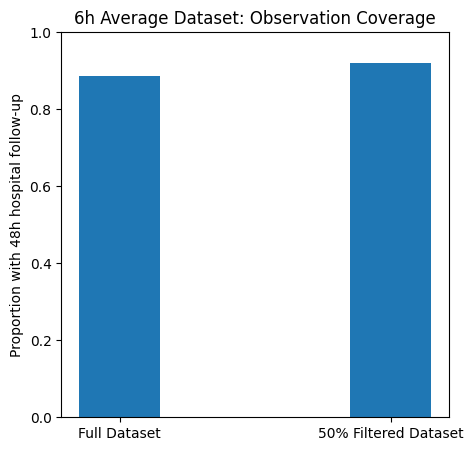

Full average dataset complete observation percentage: 88.67%
Filtered average dataset complete observation percentage: 92.02%


In [30]:
# Hospital observation coverage.
average_observation_rates = pd.Series({
    'Full Dataset': average_full_dataset['hospital_observed_48h'].mean(),
    '50% Filtered Dataset': average_filtered_dataset['hospital_observed_48h'].mean()
})
fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(average_observation_rates.index, average_observation_rates.values, width=0.3)
ax.set_ylabel('Proportion with 48h hospital follow-up')
ax.set_title(f'{INTERVAL}h Average Dataset: Observation Coverage')
ax.set_ylim(0, 1)
plt.show()
print(f'Full average dataset complete observation percentage: '
      f"{average_observation_rates['Full Dataset'] * 100:.2f}%")
print(f'Filtered average dataset complete observation percentage: '
      f"{average_observation_rates['50% Filtered Dataset'] * 100:.2f}%")

**AI Declaration**: OpenAI ChatGPT was used for brainstorm the structure, assisted with debugging code errors and refining the writing for coherence. The code have been implemented by Jiajian He  